# Figure 1, Panel F
Violin plot showing distribution of BAFinh vs Vehicle log2 fold change accessibility at enhancers, promoters, and insulators (chromHMM state annotations)

*Output: panel_f_violin.pdf*

# Setup

In [1]:
#load packages
library(tidyverse)
library(here)
here::i_am("figures/Figure1/PanelF/panel_f.ipynb")
here()

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure1/PanelF

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1  
 [5] dplyr_1.1.4     purrr_1.0.2     readr_2.1.5     tidyr_1.3.1    
 [9] tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    base64enc_0.1-3   

# Load data

In [2]:
# read in chromHMM state annotations
data <- read.delim(
  here(
    "figures", "Figure1", "PanelE",
    "consensus_filt_annot_chromHMM.tsv"
  ),
  sep = "\t"
)

# read in differential accessibility analysis, BAFinh 6h/10µM vs Vehicle
dar <- read.delim(
  here(
    "inputs", "DARs",
    "dose_10uM_DARs.tsv"
  ),
  sep = "\t"
)

# Generate figure panel

Saving 7 x 7 in image


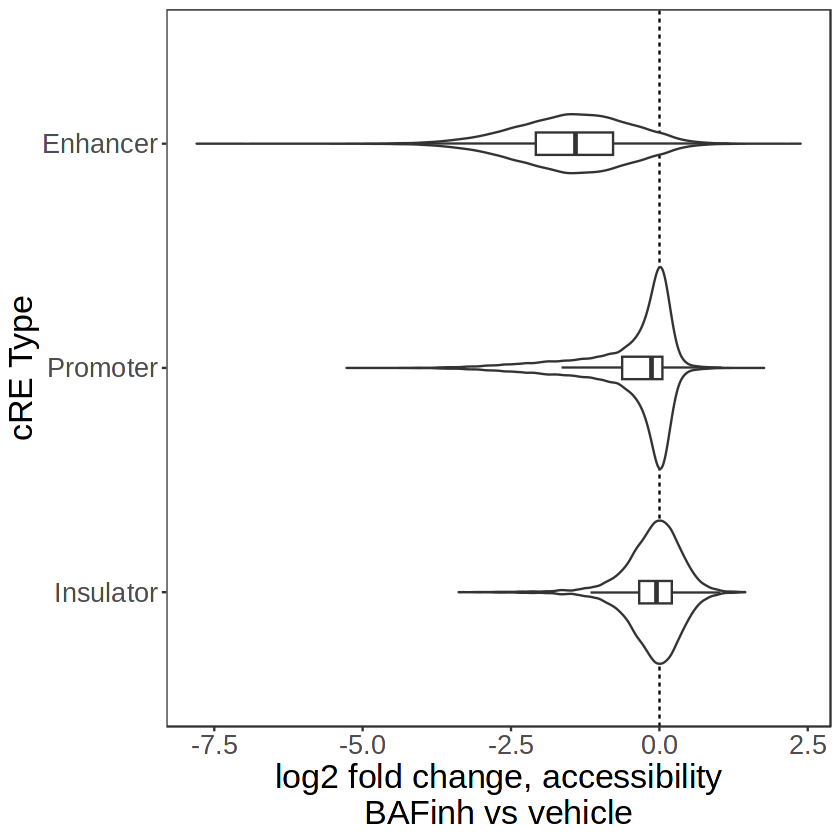

In [3]:
#generate plot
data %>% mutate(logFC=(dar %>% arrange(seqnames, start))$logFC) %>%  #add logFCs to chromHMM annotation data frame (note - need to sort DAR df first to ensure row order is same)
        filter(chromHMM_state_slim %in% c("Enhancer", "Promoter", "Insulator")) %>% #filter to only include cRE types of interest
        ggplot(aes(y=factor(chromHMM_state_slim, levels=c("Insulator", "Promoter", "Enhancer")), x=logFC))+ 
        geom_vline(xintercept=0, linetype=2) + 
        geom_violin() + geom_boxplot(outlier.shape=NA, width=.1) +
        theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=20)) + 
        xlab("log2 fold change, accessibility\nBAFinh vs vehicle") + ylab("cRE Type") 
ggsave("panel_f_violin.pdf")

# Statistics

In [4]:
#statistics:
data_slim <- data %>% mutate(logFC=(dar %>% arrange(seqnames, start))$logFC) %>% filter(chromHMM_state_slim %in% c("Enhancer", "Promoter", "Insulator"))

#Enhancer vs Promoter
wilcox.test(data_slim[data_slim$chromHMM_state_slim == "Enhancer",]$logFC, data_slim[data_slim$chromHMM_state_slim == "Promoter",]$logFC)$p.value
#Enhancer vs Insulator
wilcox.test(data_slim[data_slim$chromHMM_state_slim == "Enhancer",]$logFC, data_slim[data_slim$chromHMM_state_slim == "Insulator",]$logFC)$p.value

#Enrichment of enhancers for BAF-dep regions
fisher.test(data %>% mutate(BAFdep=(dar %>% arrange(seqnames, start))$BAFdep) %>%  #add logFCs to chromHMM annotation data frame (note - need to sort DAR df first to ensure row order is same)
        filter(chromHMM_state_slim %in% c("Enhancer", "Promoter", "Insulator")) %>%
        mutate(state=chromHMM_state_slim=="Enhancer") %>%
    select(state,BAFdep) %>% table())

[1] 0

[1] 0


	Fisher's Exact Test for Count Data

data:  data %>% mutate(BAFdep = (dar %>% arrange(seqnames, start))$BAFdep) %>% filter(chromHMM_state_slim %in% c("Enhancer", "Promoter", "Insulator")) %>% mutate(state = chromHMM_state_slim == "Enhancer") %>% select(state, BAFdep) %>% table()
p-value < 2.2e-16
alternative hypothesis: true odds ratio is not equal to 1
95 percent confidence interval:
 14.50509 15.60799
sample estimates:
odds ratio 
  15.04901 
